## Subiectul 1

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from hmmlearn import hmm
from scipy.stats import beta

start = np.array([0.25,0.25,0.25,0.25])
emission = np.array([[0.7, 0.2, 0.1],
                     [0.2, 0.6, 0.2],
                     [0.1, 0.3, 0.6],
                     [0.5, 0.2, 0.3]])
obs = np.array([[0],[1],[2],[2],[0]])

model_a=hmm.CategoricalHMM(n_components=4)
model_a.startprob_ = start
model_a.transmat_ = np.array([[0.2, 0.4, 0.0, 0.4],
                              [0.4, 0.2, 0.4, 0.0],
                              [0.0, 0.4, 0.2, 0.4],
                              [0.4, 0.0, 0.4, 0.2]])

model_a.emissionprob_ = emission
logprob_a, states_a = model_a.decode(obs, algorithm="viterbi")
print("a) camere:", states_a + 1)
print("   probabilitate (drum + observatii):", np.exp(logprob_a))

model_b=hmm.CategoricalHMM(n_components=4)
model_b.startprob_= start
model_b.transmat_ = np.array([[0.0, 0.5, 0.0, 0.5],
                              [0.5, 0.0, 0.5, 0.0],
                              [0.0, 0.5, 0.0, 0.5],
                              [0.5, 0.0, 0.5, 0.0]])
model_b.emissionprob_= emission
logprob_b, states_b = model_b.decode(obs, algorithm="viterbi")
print("b) camere:", states_b + 1)
print("   probabilitate (drum + observatii):", np.exp(logprob_b))

a) camere: [1 2 3 4 1]
   probabilitate (drum + observatii): 0.000338688
b) camere: [1 2 3 4 1]
   probabilitate (drum + observatii): 0.0008268749999999998


Comparatie a) si b)
La a) robotul ar fi putut ramane in camera 3 pentru al doilea blue.
La acel pas, ramanerea si mutarea dau acelasi scor: 0.2 * 0.6 = 0.4 * 0.3 = 0.12.
Dar din camera 3 nu se poate ajunge direct in camera 1 pentru ultimul red,
asa ca drumul prin camera 4 castiga. Deci si la a) drumul optim
nu foloseste nicio ramanere pe loc.

La b) ramanerea pe loc nu mai este posibila. Cum drumul optim de la a)
nu o folosea oricum, secventa ramane aceeasi: 1 -> 2 -> 3 -> 4 -> 1

Probabilitatea creste de la 0.000339 la 0.000827. Pe acelasi drum difera doar
cele 4 mutari: la a) fiecare are 0.4, la b) are 0.5 (probabilitatea de a ramane
pe loc se imparte intre vecini). Raportul este (0.5/0.4)^4 = 2.44.

## Subiectul 2

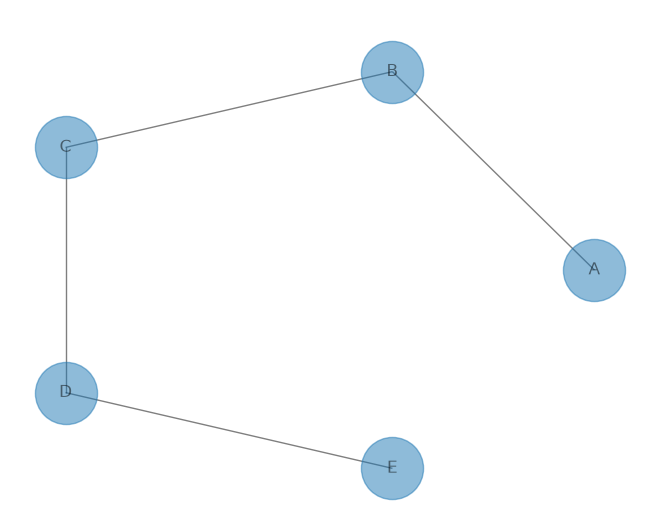

2a) P(A | B, C) = phi1(A, B) / sum_a phi1(a, B)


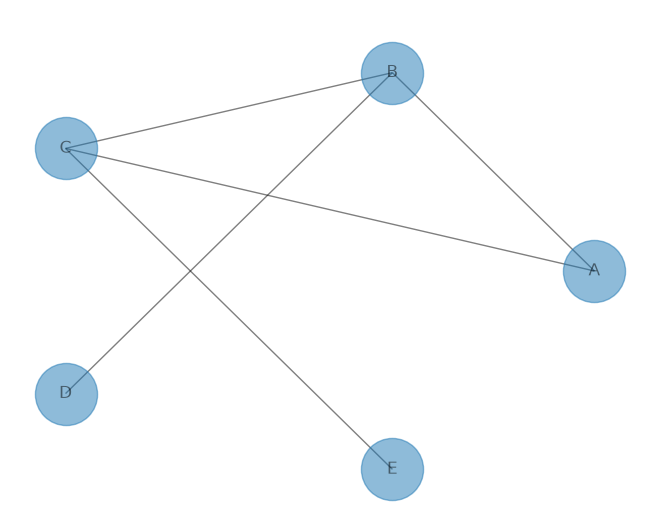

2b) P(D | A, B, C, E) = psi2(B, D) / sum_d psi2(B, d)


In [12]:
#a
G_a = nx.Graph([('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'E')])
nx.draw(G_a, with_labels=True, pos=nx.circular_layout(G_a), alpha=0.5, node_size=2000)
plt.title("2a")
plt.show()
print("2a) P(A | B, C) = phi1(A, B) / sum_a phi1(a, B)")
#b
G_b = nx.Graph([('A', 'B'), ('A', 'C'), ('B', 'C'), ('B', 'D'), ('C', 'E')])
nx.draw(G_b, with_labels=True, pos=nx.circular_layout(G_b), alpha=0.5, node_size=2000)
plt.title("2b")
plt.show()
print("2b) P(D | A, B, C, E) = psi2(B, D) / sum_d psi2(B, d)")



2a) P(A | B, C)

P(A, B, C, D, E) = 1/Z * phi1(A,B) * phi2(B,C) * phi3(C,D) * phi4(D,E)

Graful este un lant: A - B - C - D - E

P(A | B, C) = P(A, B, C) / P(B, C)

D si E nu sunt date, asa ca facem suma peste ele.
Suma sum_d sum_e phi3(C,d) * phi4(d,e) depinde doar de C, nu de A.

Tot ce nu contine A (adica 1/Z, phi2(B,C) si suma peste D, E)
apare si sus si jos, deci se simplifica.

Ramane:

P(A | B, C) = phi1(A,B) / sum_a phi1(a,B)

A este legat doar de B, deci daca stim B, C nu mai conteaza.

2b) P(D | A, B, C, E)

P(A, B, C, D, E) = 1/Z * psi1(A,B,C) * psi2(B,D) * psi3(C,E)

Muchii: A-B, A-C, B-C (clica ABC), B-D, C-E

P(D | A, B, C, E) = P(A, B, C, D, E) / sum_d P(A, B, C, d, E)

1/Z, psi1(A,B,C) si psi3(C,E) nu contin D, apar si sus si jos, deci se simplifica.

Ramane:

P(D | A, B, C, E) = psi2(B,D) / sum_d psi2(B,d)

D este legat doar de B, deci daca stim B, A, C si E nu mai conteaza.

## Subiectul 3

3a) posterior Beta (7, 23) media: 0.23333333333333334


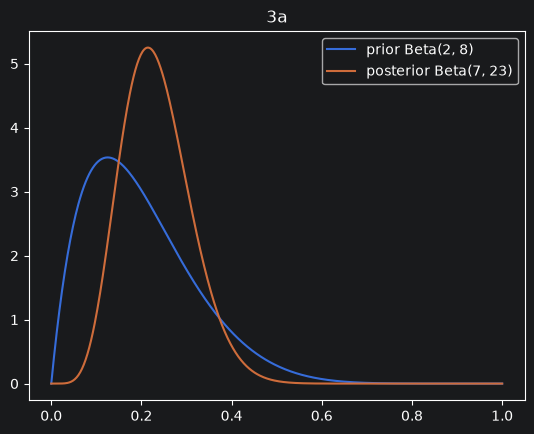

3b) posterior Beta (10, 35) media: 0.2222222222222222
3c) posterior Beta (5, 20) media: 0.2


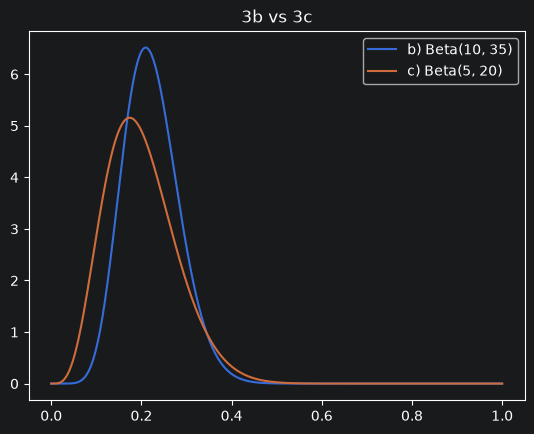

In [13]:
#a
post_a = (2 + 5, 8 + 15)   # Beta(7, 23)
print("3a) posterior Beta", post_a, "media:", post_a[0] / sum(post_a))

x = np.linspace(0, 1, 500)
plt.plot(x, beta.pdf(x, 2, 8), label="prior Beta(2, 8)")
plt.plot(x, beta.pdf(x, *post_a), label="posterior Beta(7, 23)")
plt.title("3a")
plt.legend()
plt.show()
#b
post_b = (post_a[0] + 3, post_a[1] + 12)   # Beta(10, 35)
print("3b) posterior Beta", post_b, "media:", post_b[0] / sum(post_b))
#c
post_c = (2 + 3, 8 + 12)   # Beta(5, 20)
print("3c) posterior Beta", post_c, "media:", post_c[0] / sum(post_c))

plt.plot(x, beta.pdf(x, *post_b), label="b) Beta(10, 35)")
plt.plot(x, beta.pdf(x, *post_c), label="c) Beta(5, 20)")
plt.title("3b vs 3c")
plt.legend()
plt.show()

b) foloseste ambele loturi (8 defecte din 35) -> Beta(10, 35), media 0.222.
c) foloseste doar lotul 2 (3 defecte din 15) -> Beta(5, 20), media 0.2.

Media in c) e mai mica pentru ca lotul 2 are rata 3/15 = 0.2,
iar in b) lotul 1 (rata 5/20 = 0.25) o trage in sus.

b) are mai multe date, deci posteriorul e mai ingust (mai putina incertitudine).
c) ignora lotul 1, deci e mai incert. b) este estimarea mai buna.